# 🔐 Challenge 03: Quantum Safe
### Qiskit Fall Fest Nairobi 2026 Hackathon: individual submission

## Summary (what I built, how it works, what I learned)

**What I built.** A 2-qubit Qiskit circuit that produces the target distribution `00 → 50%`, `11 → 50%`, together with a set of experiments, mathematical proofs of why it works, several alternative circuits, custom "safes", and a noise study.

**How it works.** A Hadamard gate puts qubit 0 into an equal superposition. A CNOT gate then copies that choice onto qubit 1 in a way that cannot be described by two independent qubits. The result is the **Bell state** $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt2$.

**Quantum concepts used.** Superposition, entanglement, the Born rule (measurement probabilities), global vs relative phase, gate non-commutativity, and noise.

**Results.** The Bell circuit gives roughly 50% `00` and 50% `11`, and never `01` or `10` on a perfect simulator. Removing the CNOT or swapping the gate order gives `00`/`01` instead, so the safe stays shut. Four different circuits unlock the same safe. On a noisy simulator, `01` and `10` appear.

**What I learned.** Entanglement needs a two-qubit gate. Gate order matters. Probabilities come from squared amplitudes, so phases are invisible to a direct measurement. Results are random, so the number of shots matters.

---

**Notebook map**

| Part | Content |
|---|---|
| 0 | Notation and gates |
| 1 | Main solution (Bell state) + proof |
| 2 | The four "Deeper Questions" + proofs |
| 3 | Experiments: shots, prediction vs observation |
| 4 | Stretch: multiple circuits for the same safe + proofs |
| 5 | Stretch: my own safes (50/50 anti-correlated, GHZ, 75/25) + proofs |
| 6 | Stretch: noise (and optional real hardware) |

## Part 0: Notation and gates (the math toolkit)

**Qubit.** A qubit state is $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ with $|\alpha|^2 + |\beta|^2 = 1$. The numbers $\alpha, \beta$ are *amplitudes* (can be complex or negative).

**Born rule.** Measuring gives outcome $x$ with probability $P(x) = |\text{amplitude of } x|^2$.

**Two qubits.** A state is $a|00\rangle + b|01\rangle + c|10\rangle + d|11\rangle$ with $|a|^2+|b|^2+|c|^2+|d|^2 = 1$.

**Qiskit bit order.** Qiskit writes kets as $|q_1 q_0\rangle$, so **qubit 0 is the rightmost bit**. All kets in this notebook follow that convention. As a vector in the order $(00, 01, 10, 11)$ the state is $(a, b, c, d)^T$.

**Gates used (all are unitary matrices, $U^\dagger U = I$, so they preserve total probability):**

$$H = \frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix},\quad
X = \begin{pmatrix}0&1\\1&0\end{pmatrix},\quad
Z = \begin{pmatrix}1&0\\0&-1\end{pmatrix}$$

Their actions on basis states: $H|0\rangle = \frac{|0\rangle+|1\rangle}{\sqrt2}$, $H|1\rangle = \frac{|0\rangle-|1\rangle}{\sqrt2}$, $X|0\rangle=|1\rangle$, $X|1\rangle=|0\rangle$, $Z|0\rangle=|0\rangle$, $Z|1\rangle=-|1\rangle$.

**CNOT** (control = qubit 0, target = qubit 1) flips the target only when the control is 1: $|q_1 q_0\rangle \mapsto |q_1\oplus q_0,\; q_0\rangle$. In the order $(00,01,10,11)$:

$$\text{CNOT}_{0\to1} = \begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}$$

**Applying a gate to one qubit of two.** "$H$ on qubit 0" means $I\otimes H$ (identity on qubit 1, $H$ on qubit 0).

In [1]:
# ============================================================
# Cell 1: Imports and helper functions
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile        # build circuits / adapt them to a backend
from qiskit_aer import AerSimulator                 # simulator that runs on your own computer
from qiskit.visualization import plot_histogram     # nice bar charts of results
from qiskit.quantum_info import Statevector, partial_trace, entropy  # exact maths tools

simulator = AerSimulator()


def run(circuit, shots=1024, backend=simulator):
    """Run a circuit `shots` times and return the counts, e.g. {'00': 510, '11': 514}."""
    compiled = transpile(circuit, backend)            # translate gates the backend understands
    result = backend.run(compiled, shots=shots).result()
    return result.get_counts()


def tvd(counts, target):
    """Total variation distance between observed counts and a target distribution.
    0 means a perfect match; 1 means completely different.
    `target` is a dict like {'00': 0.5, '11': 0.5}."""
    shots = sum(counts.values())
    keys = set(counts) | set(target)
    return 0.5 * sum(abs(counts.get(k, 0) / shots - target.get(k, 0)) for k in keys)


# Qiskit prints bitstrings as "q1 q0": qubit 0 is the RIGHTMOST bit.
TARGET = {"00": 0.5, "11": 0.5}   # the safe's combination
print("Setup OK")

Setup OK


## Part 1: The main solution, a Bell-state circuit

### Reading the target
`00 → 50%, 11 → 50%` says two things:
1. **Randomness:** each of the two outcomes happens half the time. This needs superposition.
2. **Agreement:** `01` and `10` never happen, so the two qubits always agree. This needs entanglement.

### Proof 1: the circuit produces $(|00\rangle+|11\rangle)/\sqrt2$

Start: $|\psi_0\rangle = |00\rangle = (1,0,0,0)^T$.

**Step 1, $H$ on qubit 0:**
$$|\psi_1\rangle = (I\otimes H)|00\rangle = |0\rangle\otimes H|0\rangle = |0\rangle\otimes\frac{|0\rangle+|1\rangle}{\sqrt2} = \frac{|00\rangle+|01\rangle}{\sqrt2}$$

**Step 2, CNOT (control 0, target 1):** apply the matrix to $\frac1{\sqrt2}(1,1,0,0)^T$:
$$|\psi_2\rangle = \frac{1}{\sqrt2}\begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}\begin{pmatrix}1\\1\\0\\0\end{pmatrix} = \frac{1}{\sqrt2}\begin{pmatrix}1\\0\\0\\1\end{pmatrix} = \frac{|00\rangle+|11\rangle}{\sqrt2} = |\Phi^+\rangle \quad\blacksquare$$

(In words: $|00\rangle$ has control 0, so nothing happens. $|01\rangle$ has control 1, so qubit 1 flips and it becomes $|11\rangle$.)

### Proof 2: the measurement probabilities (Born rule)
$$P(00) = \left|\tfrac1{\sqrt2}\right|^2 = \tfrac12,\quad P(11) = \left|\tfrac1{\sqrt2}\right|^2 = \tfrac12,\quad P(01) = |0|^2 = 0,\quad P(10) = |0|^2 = 0$$
The probabilities sum to $\tfrac12+\tfrac12 = 1$, so the state is properly normalised. This is exactly the target distribution. $\blacksquare$

In [2]:
# ============================================================
# Cell 2: THE SOLUTION. Bell-state circuit (target: 00 -> 50%, 11 -> 50%)
# ============================================================
qc = QuantumCircuit(2, 2)    # 2 qubits + 2 classical bits (to store measurement results)

qc.h(0)                      # Hadamard on qubit 0 -> (|0> + |1>)/sqrt(2)  (superposition)
qc.cx(0, 1)                  # CNOT, control=qubit 0, target=qubit 1       (entanglement)
qc.measure([0, 1], [0, 1])   # measure qubit 0 -> classical bit 0, qubit 1 -> classical bit 1

print(qc.draw())             # text drawing of the circuit

counts = run(qc, shots=1024) # run the circuit 1024 times
print("Counts:", counts)
print("Distance from target (0 = perfect):", round(tvd(counts, TARGET), 4))

plot_histogram(counts, title="Quantum Safe: Bell circuit")
plt.show()

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


Counts: {'11': 523, '00': 501}
Distance from target (0 = perfect): 0.0107


In [3]:
# ============================================================
# Cell 3: Check the maths with Qiskit's exact state-vector tool
# ============================================================
# Build the same circuit WITHOUT measurement so we can look at the quantum state itself.
qc_nm = QuantumCircuit(2)
qc_nm.h(0)
qc_nm.cx(0, 1)

sv = Statevector(qc_nm)                  # exact amplitudes, no randomness
print("Amplitudes (order 00, 01, 10, 11):")
print(np.round(sv.data, 4))              # expect [0.7071, 0, 0, 0.7071]
print("Exact probabilities:", sv.probabilities_dict())

# Entanglement check: entropy of qubit 0 on its own.
#   0 bits -> qubit is in a definite pure state (NOT entangled)
#   1 bit  -> maximally entangled with the other qubit
rho_q0 = partial_trace(sv, [1])          # "forget" qubit 1, keep qubit 0
print("Entanglement entropy of qubit 0:", round(float(entropy(rho_q0, base=2)), 4), "bit(s)")

Amplitudes (order 00, 01, 10, 11):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
Exact probabilities: {np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


Entanglement entropy of qubit 0: 1.0 bit(s)


## Part 2: The "Deeper Questions", answered with proofs

### Q1. Why do some states appear while others don't?

Only outcomes with non-zero amplitude can appear (Born rule). After $H$, the amplitude sat on $|00\rangle$ and $|01\rangle$. The CNOT is a *permutation* of the basis states: it sends $|01\rangle\to|11\rangle$ and leaves $|00\rangle$ alone. It never creates amplitude on $|01\rangle$ or $|10\rangle$ from this input, so those outcomes have probability exactly 0. $\blacksquare$

### Q2. What happens if we remove the CNOT?

**Proof 3.** After $H$ only:
$$|\psi\rangle = \frac{|00\rangle+|01\rangle}{\sqrt2} = |0\rangle\otimes\frac{|0\rangle+|1\rangle}{\sqrt2}$$
Qubit 1 is always $|0\rangle$ and qubit 0 is a fair coin. So $P(00)=P(01)=\tfrac12$ and $P(10)=P(11)=0$. The outcome `11` is impossible, so the safe stays shut. $\blacksquare$

### Q3. What happens if we change the order of the gates?

**Proof 4.** Apply CNOT first, to $|00\rangle$: the control (qubit 0) is $|0\rangle$, so nothing happens and the state stays $|00\rangle$. Then $H$ on qubit 0 gives $\frac{|00\rangle+|01\rangle}{\sqrt2}$, identical to Proof 3. So the distribution is `00`/`01` at 50% each. The safe stays shut.

In general, gates do not commute: $\text{CNOT}\,(I\otimes H) \neq (I\otimes H)\,\text{CNOT}$. We can see this because the two orders give different output states from the same input. Order matters. $\blacksquare$

### Q4. Why are the two qubits correlated?

**Proof 5 (the state is entangled).** A two-qubit state $a|00\rangle+b|01\rangle+c|10\rangle+d|11\rangle$ is a *product* of independent qubits $(x_0|0\rangle+x_1|1\rangle)\otimes(y_0|0\rangle+y_1|1\rangle)$ only if
$$a = x_0y_0,\; b = x_0y_1,\; c = x_1y_0,\; d = x_1y_1 \;\Rightarrow\; ad = x_0x_1y_0y_1 = bc.$$
So every product state satisfies $ad = bc$. For the Bell state $a=d=\tfrac1{\sqrt2}$ and $b=c=0$:
$$ad = \tfrac12 \neq 0 = bc.$$
The condition fails, so $|\Phi^+\rangle$ **cannot** be written as two independent qubits. It is entangled. $\blacksquare$

**Proof 6 (the correlation is perfect).** The conditional probability is
$$P(q_1=1 \mid q_0=1) = \frac{P(11)}{P(01)+P(11)} = \frac{1/2}{0+1/2} = 1,\qquad P(q_1=0\mid q_0=0)=\frac{P(00)}{P(00)+P(10)}=1.$$
Learning one qubit's result tells you the other with certainty, although each qubit alone is a fair coin ($P(q_0=1)=\tfrac12$). $\blacksquare$

**Proof 7 (you cannot make entanglement with one-qubit gates alone).** If the input is a product state and we apply $U_0\otimes U_1$ (one gate on each qubit), then
$$(U_0\otimes U_1)(|x\rangle\otimes|y\rangle) = (U_0|x\rangle)\otimes(U_1|y\rangle),$$
which is still a product state. So circuits made only of H, X, Z on separate qubits keep $ad=bc$ forever. A two-qubit gate such as CNOT is *required* to open this safe. $\blacksquare$

In [4]:
# ============================================================
# Cell 4: Experiment A. Remove the CNOT (prediction: only 00 and 01, safe stays shut)
# ============================================================
no_cnot = QuantumCircuit(2, 2)
no_cnot.h(0)                          # superposition on qubit 0 only
no_cnot.measure([0, 1], [0, 1])

counts_no_cnot = run(no_cnot)
print("PREDICTION: '00' ~50%, '01' ~50%, never '11'")
print("OBSERVED  :", counts_no_cnot)
print("Distance from safe target:", round(tvd(counts_no_cnot, TARGET), 3), "(far from 0 -> safe stays shut)")
plot_histogram(counts_no_cnot, title="Without CNOT")
plt.show()

# Entanglement check for this circuit: the state is a product, so entropy should be 0.
tmp = QuantumCircuit(2); tmp.h(0)     # same circuit but without measurement
print("Entanglement entropy without CNOT:", round(float(entropy(partial_trace(Statevector(tmp), [1]), base=2)), 4))

PREDICTION: '00' ~50%, '01' ~50%, never '11'
OBSERVED  : {'00': 528, '01': 496}
Distance from safe target: 0.5 (far from 0 -> safe stays shut)
Entanglement entropy without CNOT: 0.0


In [5]:
# ============================================================
# Cell 5: Experiment B. Swap the order (CNOT before H)
# ============================================================
swapped = QuantumCircuit(2, 2)
swapped.cx(0, 1)             # control qubit is still |0>, so the CNOT does nothing
swapped.h(0)                 # THEN put qubit 0 into superposition
swapped.measure([0, 1], [0, 1])

counts_swapped = run(swapped)
print("PREDICTION: same as 'no CNOT': '00' and '01' only")
print("OBSERVED  :", counts_swapped)
print("Distance from safe target:", round(tvd(counts_swapped, TARGET), 3))
plot_histogram(counts_swapped, title="CNOT before H")
plt.show()

PREDICTION: same as 'no CNOT': '00' and '01' only
OBSERVED  : {'01': 541, '00': 483}
Distance from safe target: 0.528


## Part 3: Experiments on shots (randomness vs sample size)

**Proof 8 (how close to 50/50 should we expect to get?).** Each shot is an independent trial with success probability $p=\tfrac12$ (getting `00`). With $N$ shots the observed fraction $\hat p$ has
$$\mathbb E[\hat p] = p,\qquad \sigma(\hat p) = \sqrt{\frac{p(1-p)}{N}} = \frac{1}{2\sqrt N}.$$

| Shots $N$ | $\sigma$ | typical deviation ($\pm 2\sigma$) |
|---:|---:|---:|
| 10 | 0.158 | ±31.6% |
| 100 | 0.050 | ±10% |
| 1,024 | 0.0156 | ±3.1% |
| 10,000 | 0.005 | ±1% |

So $01$ or $10$ never appearing is a **property of the circuit** (probability exactly 0), whereas the exact `00`/`11` split only *approaches* 50/50 as $N$ grows. Quadrupling the shots halves the error. $\blacksquare$

  shots |   P(00) |   P(11) | |P(00)-0.5| | theory sigma | other outcomes


     10 |   0.400 |   0.600 |      0.1000 |       0.1581 | 0


    100 |   0.520 |   0.480 |      0.0200 |       0.0500 | 0


   1000 |   0.507 |   0.493 |      0.0070 |       0.0158 | 0
  10000 |   0.495 |   0.505 |      0.0054 |       0.0050 | 0


 100000 |   0.500 |   0.500 |      0.0002 |       0.0016 | 0



200 repeats at 1024 shots: mean P(00) = 0.4988, std = 0.0164  (theory: 0.0156)


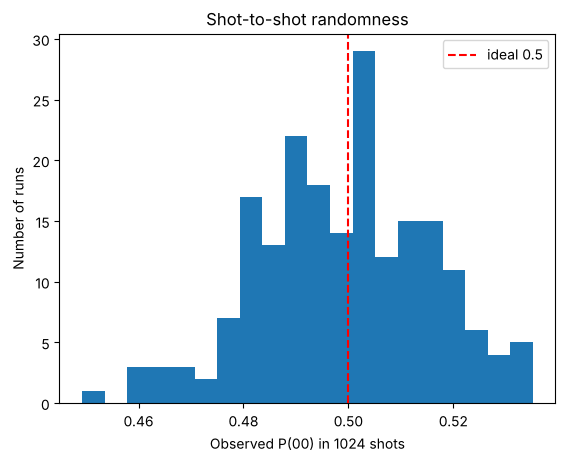

In [6]:
# ============================================================
# Cell 6: Experiment C. How the number of shots changes the results
# ============================================================
# Prediction: the error shrinks like 1/(2*sqrt(N)). Compare observed vs theoretical sigma.
print(f"{'shots':>7} | {'P(00)':>7} | {'P(11)':>7} | {'|P(00)-0.5|':>11} | {'theory sigma':>12} | other outcomes")
for shots in [10, 100, 1000, 10000, 100000]:
    c = run(qc, shots=shots)
    p00 = c.get("00", 0) / shots
    p11 = c.get("11", 0) / shots
    others = c.get("01", 0) + c.get("10", 0)
    sigma = 1 / (2 * np.sqrt(shots))
    print(f"{shots:>7} | {p00:>7.3f} | {p11:>7.3f} | {abs(p00 - 0.5):>11.4f} | {sigma:>12.4f} | {others}")

# Repeat the 1024-shot experiment many times to see the spread directly.
results = [run(qc, shots=1024).get("00", 0) / 1024 for _ in range(200)]
print(f"\n200 repeats at 1024 shots: mean P(00) = {np.mean(results):.4f}, "
      f"std = {np.std(results):.4f}  (theory: {1 / (2 * np.sqrt(1024)):.4f})")
plt.hist(results, bins=20)
plt.axvline(0.5, color="red", linestyle="--", label="ideal 0.5")
plt.xlabel("Observed P(00) in 1024 shots"); plt.ylabel("Number of runs"); plt.legend()
plt.title("Shot-to-shot randomness")
plt.show()

## Part 4 (Stretch): Different circuits, same safe

**Circuit 1, standard:** $H_0$, then CNOT$_{0\to1}$. Proven above: $|\Phi^+\rangle$.

**Circuit 2, roles reversed:** $H_1$, then CNOT$_{1\to0}$.
**Proof 9.** $H_1|00\rangle = \frac{|00\rangle+|10\rangle}{\sqrt2}$. CNOT with control 1 and target 0 flips qubit 0 when qubit 1 is 1: $|10\rangle\to|11\rangle$. Result $\frac{|00\rangle+|11\rangle}{\sqrt2}=|\Phi^+\rangle$. $\blacksquare$

**Circuit 3, extra Z gate.** Apply $Z$ to qubit 0 of $|\Phi^+\rangle$. $Z$ multiplies by $(-1)^{q_0}$: $|00\rangle\to|00\rangle$, $|11\rangle\to-|11\rangle$.
**Proof 10.**
$$Z_0|\Phi^+\rangle = \frac{|00\rangle-|11\rangle}{\sqrt2}=|\Phi^-\rangle,\qquad P(00)=\left|\tfrac1{\sqrt2}\right|^2=\tfrac12,\; P(11)=\left|\tfrac{-1}{\sqrt2}\right|^2=\tfrac12.$$
The minus sign is a *relative phase*. The Born rule squares the amplitude, so it disappears from direct measurement and the distribution is identical. (It would matter if we applied more gates that make the amplitudes interfere. For example, $H$ on both qubits turns $|\Phi^+\rangle$ into outcomes `00`/`11` but $|\Phi^-\rangle$ into `01`/`10`.) $\blacksquare$

**Circuit 4, CNOT built from H and CZ.** Controlled-Z is $CZ=|0\rangle\langle0|\otimes I+|1\rangle\langle1|\otimes Z$ (control $\otimes$ target).
**Proof 11.** Conjugating the target by $H$ and using $HZH=X$:
$$(I\otimes H)\,CZ\,(I\otimes H)=|0\rangle\langle0|\otimes HIH+|1\rangle\langle1|\otimes HZH=|0\rangle\langle0|\otimes I+|1\rangle\langle1|\otimes X = \text{CNOT}.$$
Check $HZH=X$: $HZH=\frac12\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1&0\\0&-1\end{pmatrix}\begin{pmatrix}1&1\\1&-1\end{pmatrix}=\frac12\begin{pmatrix}1&-1\\1&1\end{pmatrix}\begin{pmatrix}1&1\\1&-1\end{pmatrix}=\frac12\begin{pmatrix}0&2\\2&0\end{pmatrix}=X.$ $\blacksquare$

In [7]:
# ============================================================
# Cell 7: Four different circuits, one safe combination
# ============================================================
# Circuit 1: standard (H on q0, CNOT 0 -> 1)
c1 = QuantumCircuit(2, 2)
c1.h(0); c1.cx(0, 1)
c1.measure([0, 1], [0, 1])

# Circuit 2: roles reversed (H on q1, CNOT 1 -> 0)
c2 = QuantumCircuit(2, 2)
c2.h(1); c2.cx(1, 0)
c2.measure([0, 1], [0, 1])

# Circuit 3: add a Z gate. State becomes (|00> - |11>)/sqrt(2): a relative phase only.
c3 = QuantumCircuit(2, 2)
c3.h(0); c3.cx(0, 1); c3.z(0)
c3.measure([0, 1], [0, 1])

# Circuit 4: build the CNOT out of H-CZ-H on the target qubit (proof 11)
c4 = QuantumCircuit(2, 2)
c4.h(0)
c4.h(1); c4.cz(0, 1); c4.h(1)       # this sandwich equals cx(0, 1)
c4.measure([0, 1], [0, 1])

circuits = {"1: H + CX": c1, "2: reversed": c2, "3: with Z": c3, "4: H + CZ + H": c4}
all_counts = {name: run(c, shots=4096) for name, c in circuits.items()}
for name, cnt in all_counts.items():
    print(f"{name:<15} {cnt}   distance from target = {tvd(cnt, TARGET):.4f}")

plot_histogram(list(all_counts.values()), legend=list(all_counts.keys()),
               title="Four circuits, one safe")
plt.show()

1: H + CX       {'00': 2015, '11': 2081}   distance from target = 0.0081
2: reversed     {'00': 2080, '11': 2016}   distance from target = 0.0078
3: with Z       {'11': 2050, '00': 2046}   distance from target = 0.0005
4: H + CZ + H   {'11': 2101, '00': 1995}   distance from target = 0.0129


In [8]:
# ============================================================
# Cell 8: Phase is invisible to measurement but not to interference
# ============================================================
# Bell state with a minus sign: (|00> - |11>)/sqrt(2). Direct measurement looks identical.
# Now apply H to BOTH qubits before measuring: the hidden phase becomes visible.
def bell_then_hh(with_z):
    q = QuantumCircuit(2, 2)
    q.h(0); q.cx(0, 1)
    if with_z:
        q.z(0)                   # flips the relative sign
    q.h(0); q.h(1)               # makes the two paths interfere
    q.measure([0, 1], [0, 1])
    return q

print("Phi+ then H,H :", run(bell_then_hh(False)))   # expect only 00 and 11
print("Phi- then H,H :", run(bell_then_hh(True)))    # expect only 01 and 10

Phi+ then H,H : {'11': 518, '00': 506}


Phi- then H,H : {'10': 496, '01': 528}


## Part 5 (Stretch): Design my own safes

### Safe A: `01 → 50%, 10 → 50%` (qubits always disagree)
Make $|\Phi^+\rangle$, then apply $X$ to qubit 0, which flips the rightmost bit.

**Proof 12.** $X_0$ maps $|00\rangle\to|01\rangle$ and $|11\rangle\to|10\rangle$, so
$$X_0|\Phi^+\rangle=\frac{|01\rangle+|10\rangle}{\sqrt2}=|\Psi^+\rangle,\qquad P(01)=P(10)=\tfrac12,\; P(00)=P(11)=0.\;\blacksquare$$

### Safe B: 3 qubits, `000 → 50%, 111 → 50%` (GHZ state)
$H_0$, then CNOT$_{0\to1}$, then CNOT$_{0\to2}$.

**Proof 13.** $|000\rangle\xrightarrow{H_0}\frac{|000\rangle+|001\rangle}{\sqrt2}\xrightarrow{CX_{0\to1}}\frac{|000\rangle+|011\rangle}{\sqrt2}\xrightarrow{CX_{0\to2}}\frac{|000\rangle+|111\rangle}{\sqrt2}$.
Each CNOT acts only when qubit 0 is 1, so the branch $|001\rangle$ becomes $|011\rangle$ and then $|111\rangle$. Probabilities: $P(000)=P(111)=\tfrac12$. $\blacksquare$

### Safe C: unequal probabilities, `00 → 75%, 11 → 25%`
We need amplitudes $\sqrt{0.75}$ and $\sqrt{0.25}$ instead of $\tfrac1{\sqrt2}$. Use a rotation about the Y axis:
$$R_Y(\theta)|0\rangle=\cos\tfrac\theta2|0\rangle+\sin\tfrac\theta2|1\rangle.$$

**Proof 14.** We want $P(q_0=0)=\cos^2\tfrac\theta2=0.75$, so $\cos\tfrac\theta2=\tfrac{\sqrt3}{2}$, giving $\tfrac\theta2=\tfrac\pi6$ and $\theta=\tfrac\pi3$. The state after $R_Y$ is $\frac{\sqrt3}{2}|00\rangle+\frac12|01\rangle$. CNOT then moves $|01\rangle\to|11\rangle$:
$$\frac{\sqrt3}{2}|00\rangle+\frac12|11\rangle,\qquad P(00)=\tfrac34,\;P(11)=\tfrac14.\;\blacksquare$$

**General recipe.** For any target "$00\to p$, $11\to1-p$", use $\theta=2\arccos\sqrt p$.

In [9]:
# ============================================================
# Cell 9: Safe A (anti-correlated), Safe B (3-qubit GHZ), Safe C (75/25)
# ============================================================
# --- Safe A: "01 -> 50%, 10 -> 50%" ---
safe_a = QuantumCircuit(2, 2)
safe_a.h(0); safe_a.cx(0, 1)      # Bell pair
safe_a.x(0)                       # flip qubit 0: |00> -> |01>, |11> -> |10>
safe_a.measure([0, 1], [0, 1])
ca = run(safe_a, 2048)
print("Safe A:", ca, " distance:", round(tvd(ca, {"01": .5, "10": .5}), 4))

# --- Safe B: "000 -> 50%, 111 -> 50%" (GHZ state) ---
safe_b = QuantumCircuit(3, 3)
safe_b.h(0)
safe_b.cx(0, 1)
safe_b.cx(0, 2)
safe_b.measure([0, 1, 2], [0, 1, 2])
cb = run(safe_b, 2048)
print("Safe B:", cb, " distance:", round(tvd(cb, {"000": .5, "111": .5}), 4))

# --- Safe C: "00 -> 75%, 11 -> 25%" ---
def make_safe(p00):
    """Return a circuit giving 00 with probability p00 and 11 with probability 1-p00."""
    theta = 2 * np.arccos(np.sqrt(p00))     # from cos^2(theta/2) = p00
    q = QuantumCircuit(2, 2)
    q.ry(theta, 0)                           # unequal superposition on qubit 0
    q.cx(0, 1)                               # copy the choice onto qubit 1
    q.measure([0, 1], [0, 1])
    return q

safe_c = make_safe(0.75)
cc = run(safe_c, 8000)
print("Safe C:", cc, " distance:", round(tvd(cc, {"00": .75, "11": .25}), 4))

# Try a few other combinations with the same recipe
for p in [0.9, 0.5, 0.2]:
    c = run(make_safe(p), 8000)
    print(f"p(00)={p}: observed P(00)={c.get('00', 0) / 8000:.3f}")

plot_histogram([ca, cc], legend=["Safe A (01/10)", "Safe C (75/25)"], title="Custom safes")
plt.show()
plot_histogram(cb, title="Safe B (3-qubit GHZ)")
plt.show()

Safe A: {'01': 1046, '10': 1002}  distance: 0.0107


Safe B: {'111': 1030, '000': 1018}  distance: 0.0029


Safe C: {'11': 2028, '00': 5972}  distance: 0.0035


p(00)=0.9: observed P(00)=0.899


p(00)=0.5: observed P(00)=0.496


p(00)=0.2: observed P(00)=0.203


## Part 6 (Stretch): Quantum noise

Real quantum computers are imperfect, so gates sometimes introduce errors. A **depolarizing error** with probability $\epsilon$ replaces the state with a completely random one with probability $\epsilon$.

**Exact error prediction (Proof 15).** Qiskit's depolarizing error with probability $\epsilon$ replaces the state of the affected qubits with the maximally mixed state $I/d$ with probability $\epsilon$, and leaves it untouched otherwise.

- *Noise on H (1 qubit, $\epsilon_1$).* If it strikes, qubit 0 becomes a random coin $\rho=I/2$ before the CNOT. The CNOT still copies qubit 0 onto qubit 1, so the outputs are still `00` or `11` (each 50%). **This noise causes no forbidden outcomes.**
- *Noise on the CNOT (2 qubits, $\epsilon_2$).* If it strikes, both qubits become maximally mixed, so all four outcomes `00, 01, 10, 11` are equally likely (25% each). Half of those, `01` and `10`, are forbidden.

So the leakage into forbidden states is
$$P(\{01,10\}) = \epsilon_2\cdot\tfrac12 = \tfrac{\epsilon_2}{2}.$$
For $\epsilon_2 = 5\%$ this is **2.5%**, and the simulation in Cell 10 gives 2.49%. For the sweep $\epsilon_2 = 2\%, 5\%, 10\%, 20\%$ the formula predicts $1\%, 2.5\%, 5\%, 10\%$. $\blacksquare$

The key lesson: perfect-simulator results show `01` and `10` at exactly 0%, but on noisy hardware they show up with small non-zero probability. So "approximately this distribution" in the challenge text is meaningful.

In [10]:
# ============================================================
# Cell 10: Noisy simulation
# ============================================================
from qiskit_aer.noise import NoiseModel, depolarizing_error

noise_model = NoiseModel()
# 2% error on 1-qubit gates, 5% error on CNOTs (two-qubit gates are the noisiest on real devices)
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.02, 1), ["h", "x", "z"])
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.05, 2), ["cx"])

noisy_sim = AerSimulator(noise_model=noise_model)

shots = 20000
ideal_counts = run(qc, shots=shots)
noisy_counts = run(qc, shots=shots, backend=noisy_sim)

print("Ideal:", ideal_counts)
print("Noisy:", noisy_counts)
leak = (noisy_counts.get("01", 0) + noisy_counts.get("10", 0)) / shots
print(f"Fraction of shots in forbidden states 01/10: {leak:.3%}   (theory: eps2/2 = 2.500%)")
print("Distance from target, ideal:", round(tvd(ideal_counts, TARGET), 4),
      "| noisy:", round(tvd(noisy_counts, TARGET), 4))

plot_histogram([ideal_counts, noisy_counts], legend=["Ideal", "Noisy"], title="Ideal vs noisy safe")
plt.show()

# How does the error grow with CNOT noise?
print("\nCNOT error -> fraction in 01/10")
for eps in [0.0, 0.02, 0.05, 0.10, 0.20]:
    nm = NoiseModel()
    if eps > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(eps, 2), ["cx"])
    sim = AerSimulator(noise_model=nm)
    c = run(qc, shots=shots, backend=sim)
    print(f"  {eps:>4.2f} -> {(c.get('01', 0) + c.get('10', 0)) / shots:.3%}")

Ideal: {'11': 9921, '00': 10079}
Noisy: {'01': 271, '11': 9727, '10': 249, '00': 9753}
Fraction of shots in forbidden states 01/10: 2.600%   (theory: eps2/2 = 2.500%)
Distance from target, ideal: 0.004 | noisy: 0.026

CNOT error -> fraction in 01/10
  0.00 -> 0.000%
  0.02 -> 1.015%
  0.05 -> 2.575%


  0.10 -> 5.160%
  0.20 -> 9.775%


### Optional: run on real IBM quantum hardware (bonus)

The cell below is commented out because it needs a free IBM Quantum account and an API token. To use it: create an account at quantum.cloud.ibm.com, copy your API key, install `pip install qiskit-ibm-runtime`, then remove the `#` signs.

Expected outcome: mostly `00` and `11` (about 45–50% each) with a few percent in `01`/`10` caused by hardware noise, which matches the noisy simulation above.

In [11]:
# ============================================================
# Cell 11: (OPTIONAL) Real hardware. Uncomment after setting up an IBM Quantum account
# ============================================================
# from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
# from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
#
# service = QiskitRuntimeService(channel="ibm_quantum_platform", token="YOUR_API_KEY")
# backend = service.least_busy(operational=True, simulator=False)     # pick the least busy real device
# pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
# isa_circuit = pm.run(qc)                                            # adapt circuit to the real chip
# job = Sampler(mode=backend).run([isa_circuit], shots=1024)
# real_counts = job.result()[0].data.c.get_counts()                   # 'c' = name of the classical register
# print(real_counts)
# plot_histogram([ideal_counts, real_counts], legend=["Simulator", backend.name])
print("Skipped real-hardware run (optional).")

Skipped real-hardware run (optional).


## Conclusion and what I learned

| Question | Answer |
|---|---|
| How do you unlock the safe? | $H$ on qubit 0, then CNOT 0→1 produces $(|00\rangle+|11\rangle)/\sqrt2$. |
| Why only `00` and `11`? | Only those basis states have non-zero amplitude (Proofs 1-2). |
| Without the CNOT? | Qubit 1 stays $|0\rangle$: results are `00`/`01` (Proof 3). |
| Order swapped? | CNOT sees control $|0\rangle$ and does nothing: results are `00`/`01` (Proof 4). |
| Why correlated? | The state is entangled: $ad\neq bc$ (Proof 5) and conditional probability is 1 (Proof 6). One-qubit gates alone can't do this (Proof 7). |
| Why isn't it exactly 50/50? | Statistical error $\approx 1/(2\sqrt N)$ (Proof 8). |
| Other circuits for the same safe? | Reversed roles, extra Z (phase only), H-CZ-H (Proofs 9-11). |
| Own safes? | Anti-correlated, GHZ, and arbitrary $p$ via $R_Y(2\arccos\sqrt p)$ (Proofs 12-14). |
| Real devices? | Leakage into forbidden states equals $\epsilon_2/2$ (Proof 15). |

**Reflection.** The biggest lesson for me was that measurement hides phase, but later gates can reveal it (Cell 8). The second was that a good result needs both a working circuit and an understanding of *why* it works, which is why each experiment above has a prediction written before the observation.

*AI tools were used to help draft this notebook, and I have worked through each proof and cell so that I can explain them in my own words.*